# 1. Title and One-Paragraph Summary
**Stadium Gate Entry: How Many Security Lanes Keep the Queue Safe?**

This notebook models pre-match spectator arrivals at a Sri Lankan cricket stadium gate as a discrete-event $M/M/c$ security-screening queue (and extends to a two-stage ticket-check and security-screening network under a time-varying arrival surge). Using synthetic, literature-grounded parameters, next-event time-advance simulations with inverse-transform exponential sampling are run across multiple random seeds to compute 95% confidence intervals for 95th-percentile waiting time and peak queue length. The simulator is verified against exact Erlang-C queueing formulas, a zero-arrival limiting case, and people-conservation checks to identify the minimum lane count that keeps waiting under 10 minutes and forecourt queue build-up within safe holding capacity.


# 2. Problem and Question
Before a major cricket match at a Sri Lankan stadium, thousands of spectators arrive in a surge and must clear gate security screening. Too few lanes cause long waits and crowd build-up outside the gate; too many waste staff.

**Core Question:** What is the minimum number of security lanes per gate that keeps the **95th-percentile wait below 10 minutes** and the **peak queue length within the safe holding capacity of the forecourt** (assumed safe holding limit: 250 spectators per gate)?

**Data & Privacy Note:** Synthetic/literature-grounded parameters are used so no personal or identifiable crowd data is collected, aligned with privacy rules and crowd-flow/event-security guidance.


# 3. Model, Assumptions and Equations
We model a stadium gate security checkpoint as an $M/M/c$ queue with $c$ parallel security lanes, Poisson arrivals at rate $\lambda$ (spectators/min), and exponential service times per lane at rate $\mu$ (spectators/min/lane), so total service capacity is $c\mu$ and utilization is:
$$\rho = \frac{\lambda}{c\mu}, \quad \rho < 1 \text{ for steady-state stability}$$

Inter-arrival and service variates are generated via inverse-transform sampling from $U \sim \text{Uniform}(0,1)$:
$$X = -\frac{\ln(1 - U)}{\text{rate}}$$

For steady-state $M/M/c$ with offered load $a = \lambda/\mu$ and $\rho < 1$, the Erlang-C probability of waiting ($P_w$) and mean queue wait ($W_q$) are:
$$P_w = \frac{\frac{a^c}{c!(1-\rho)}}{\sum_{k=0}^{c-1}\frac{a^k}{k!} + \frac{a^c}{c!(1-\rho)}}, \qquad W_q = \frac{P_w}{c\mu - \lambda}$$

For the two-stage surge extension (ticket check $\to$ security screening) under a time-varying arrival rate $\lambda(t)$, arrivals are generated using Lewis-Shedler thinning with dominating rate $\lambda_{\max} \ge \lambda(t)$.

| Equation / Method | Module Topic Link |
| :--- | :--- |
| Next-event time-advance event loop & $M/M/c$ queue state transitions | Discrete-event simulation and queueing (primary) |
| Inverse-transform sampling & thinning for non-homogeneous arrivals | Input modelling and random variate generation (supporting) |
| Multi-seed replications, 95% t-confidence intervals & $N^{-1/2}$ error check | Monte Carlo integration and the law of large numbers (supporting) |


# 4. Implementation
The code below installs/imports packages, sets deterministic seeds, implements the next-event $M/M/c$ simulator and two-stage surge model, and defines helper functions for Erlang-C and 95% confidence intervals.


In [12]:
!pip install -q numpy scipy matplotlib pandas

import heapq
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

BASE_SEED = 20261127
rng = np.random.default_rng(BASE_SEED)
print(f"Ready | NumPy {np.__version__} | SciPy {scipy.__version__} | Seed {BASE_SEED}")

Ready | NumPy 2.4.6 | SciPy 1.16.3 | Seed 20261127


In [13]:
def sample_exp(local_rng, rate):
    """Inverse-transform sample from Exp(rate) where rate is events/min."""
    if rate <= 0.0:
        return math.inf
    u = local_rng.random()
    return -math.log1p(-u) / rate


def erlang_c_metrics(lam, mu, c):
    """Exact steady-state M/M/c probability of waiting (Pw) and mean queue wait (Wq, min)."""
    if lam <= 0.0:
        return 0.0, 0.0
    rho = lam / (c * mu)
    if rho >= 1.0:
        return 1.0, math.inf
    a = lam / mu
    terms = [math.exp(k * math.log(a) - math.lgamma(k + 1)) for k in range(c)]
    sum_terms = sum(terms)
    c_term = math.exp(c * math.log(a) - math.lgamma(c + 1)) / (1.0 - rho)
    pw = c_term / (sum_terms + c_term)
    wq = pw / (c * mu - lam)
    return pw, wq


def simulate_mmc(lam, mu, c, sim_time=360.0, warmup=60.0, seed=42):
    """
    Next-event time-advance discrete-event simulation of an M/M/c queue.
    Returns post-warmup mean wait (min), 95th-percentile wait (min),
    probability of waiting, peak queue length (spectators), and conservation counts.
    """
    local_rng = np.random.default_rng(seed)
    t = 0.0
    next_arrival = sample_exp(local_rng, lam)
    busy_departures = []  # min-heap of service completion times
    queue_arrivals = []   # FIFO queue of (arrival_time, after_warmup_bool)

    waits_obs = []
    waited_obs = []
    q_hist_t = [0.0]
    q_hist_len = [0]

    arrivals = 0
    departures = 0

    while True:
        next_dep = busy_departures[0] if busy_departures else math.inf
        t_next = min(next_arrival, next_dep)
        if math.isinf(t_next) or t_next > sim_time:
            break

        t = t_next
        if next_arrival <= next_dep:
            arrivals += 1
            if len(busy_departures) < c:
                if t >= warmup:
                    waits_obs.append(0.0)
                    waited_obs.append(0)
                heapq.heappush(busy_departures, t + sample_exp(local_rng, mu))
            else:
                queue_arrivals.append((t, t >= warmup))
                q_hist_t.append(t)
                q_hist_len.append(len(queue_arrivals))
            next_arrival = t + sample_exp(local_rng, lam)
        else:
            departures += 1
            heapq.heappop(busy_departures)
            if queue_arrivals:
                arr_t, after_w = queue_arrivals.pop(0)
                q_hist_t.append(t)
                q_hist_len.append(len(queue_arrivals))
                wait_min = t - arr_t
                if after_w:
                    waits_obs.append(wait_min)
                    waited_obs.append(1 if wait_min > 1e-12 else 0)
                heapq.heappush(busy_departures, t + sample_exp(local_rng, mu))

    # Conservation invariant: total arrivals = total departures + in queue + in service
    assert arrivals == departures + len(queue_arrivals) + len(busy_departures), (
        f"Conservation error: arr={arrivals}, dep={departures}, "
        f"q={len(queue_arrivals)}, busy={len(busy_departures)}"
    )

    q_t_arr = np.array(q_hist_t)
    q_len_arr = np.array(q_hist_len)
    post_mask = q_t_arr >= warmup
    peak_q = int(q_len_arr[post_mask].max()) if np.any(post_mask) else int(q_len_arr.max())

    return {
        "mean_wq": float(np.mean(waits_obs)) if waits_obs else 0.0,
        "p95_wq": float(np.percentile(waits_obs, 95)) if waits_obs else 0.0,
        "prob_wait": float(np.mean(waited_obs)) if waited_obs else 0.0,
        "peak_q": peak_q,
        "arrivals": arrivals,
        "departures": departures,
    }


def simulate_two_stage_surge(c_ticket=4, c_sec=8, mu_ticket=6.0, mu_sec=3.0,
                             peak_lam=24.0, horizon_min=120.0, seed=100):
    """
    Extension X3: Two-stage queue (Stage 1 ticket check -> Stage 2 security screening)
    with time-varying arrival surge peaking at t = 75 min.
    """
    local_rng = np.random.default_rng(seed)

    def lam_of_t(tau):
        return max(2.0, peak_lam * math.exp(-0.5 * ((tau - 75.0) / 22.0) ** 2))

    lam_max = lam_of_t(75.0)

    def next_surge_arrival(current_t):
        cand = current_t
        while True:
            cand += sample_exp(local_rng, lam_max)
            if cand > horizon_min:
                return math.inf
            if local_rng.random() <= lam_of_t(cand) / lam_max:
                return cand

    t = 0.0
    t_arr = next_surge_arrival(0.0)
    s1_busy, s1_q = [], []
    s2_busy, s2_q = [], []
    w1, w2 = [], []
    peak_q1, peak_q2 = 0, 0
    arr_total, exit_total = 0, 0

    while True:
        next_s1 = s1_busy[0] if s1_busy else math.inf
        next_s2 = s2_busy[0] if s2_busy else math.inf
        t_next = min(t_arr, next_s1, next_s2)
        if math.isinf(t_next):
            break
        t = t_next

        if t_arr <= next_s1 and t_arr <= next_s2:
            arr_total += 1
            if len(s1_busy) < c_ticket:
                w1.append(0.0)
                heapq.heappush(s1_busy, t + sample_exp(local_rng, mu_ticket))
            else:
                s1_q.append(t)
                peak_q1 = max(peak_q1, len(s1_q))
            t_arr = next_surge_arrival(t)

        elif next_s1 <= next_s2:
            heapq.heappop(s1_busy)
            if s1_q:
                w1.append(t - s1_q.pop(0))
                heapq.heappush(s1_busy, t + sample_exp(local_rng, mu_ticket))
            if len(s2_busy) < c_sec:
                w2.append(0.0)
                heapq.heappush(s2_busy, t + sample_exp(local_rng, mu_sec))
            else:
                s2_q.append(t)
                peak_q2 = max(peak_q2, len(s2_q))
        else:
            heapq.heappop(s2_busy)
            exit_total += 1
            if s2_q:
                w2.append(t - s2_q.pop(0))
                heapq.heappush(s2_busy, t + sample_exp(local_rng, mu_sec))

    assert arr_total == exit_total + len(s1_q) + len(s1_busy) + len(s2_q) + len(s2_busy)
    return {
        "mean_w1_min": float(np.mean(w1)) if w1 else 0.0,
        "mean_w2_min": float(np.mean(w2)) if w2 else 0.0,
        "peak_q1": peak_q1,
        "peak_q2": peak_q2,
        "arrivals": arr_total,
        "exits": exit_total,
    }


# 5. Verification
We verify the discrete-event engine using three checks: (1) comparison against exact steady-state Erlang-C mean queue wait ($W_q$) and probability of waiting ($P_w$), (2) the zero-arrival limiting case ($\lambda \to 0$ produces zero queue and zero wait), and (3) people conservation (`arrivals == departures + in_queue + in_service`) enforced by `assert`.


In [14]:
lam_test, mu_test, c_test = 10.0, 3.0, 4
pw_analytic, wq_analytic = erlang_c_metrics(lam_test, mu_test, c_test)

ver_runs = [
    simulate_mmc(lam_test, mu_test, c_test, sim_time=600.0, warmup=100.0, seed=100 + i)
    for i in range(15)
]
wq_sim_mean = float(np.mean([r["mean_wq"] for r in ver_runs]))
pw_sim_mean = float(np.mean([r["prob_wait"] for r in ver_runs]))

rel_err_wq = abs(wq_sim_mean - wq_analytic) / wq_analytic
abs_err_pw = abs(pw_sim_mean - pw_analytic)

print(f"Erlang-C Wq: {wq_analytic:.3f} min | Sim mean Wq: {wq_sim_mean:.3f} min | Rel err: {rel_err_wq:.2%}")
print(f"Erlang-C Pw: {pw_analytic:.3f}     | Sim mean Pw: {pw_sim_mean:.3f}     | Abs err: {abs_err_pw:.3f}")

assert rel_err_wq < 0.15, f"Relative error in Wq too high: {rel_err_wq:.2%}"
assert abs_err_pw < 0.05, f"Absolute error in Pw too high: {abs_err_pw:.3f}"

zero_run = simulate_mmc(0.0, mu_test, c_test, sim_time=120.0, warmup=10.0, seed=999)
assert zero_run["arrivals"] == 0 and zero_run["peak_q"] == 0 and zero_run["mean_wq"] == 0.0

print("All verification assertions passed (Erlang-C, zero-arrival limit, and conservation).")


Erlang-C Wq: 0.329 min | Sim mean Wq: 0.293 min | Rel err: 10.86%
Erlang-C Pw: 0.658     | Sim mean Pw: 0.641     | Abs err: 0.017
All verification assertions passed (Erlang-C, zero-arrival limit, and conservation).


# 6. Experiments and Results
We sweep security lane counts $c \in \{6, 7, 8, 9, 10, 11\}$ across 25 random seeds per lane count with 95% t-confidence intervals, alongside extensions **X2** ($N^{-1/2}$ Monte Carlo error scaling), **X3** (two-stage surge simulation), and **X5** (sensitivity across arrival and service rates).


Lane sweep completed in 3.51 s


,Lanes (c),rho,Mean Wq (min),P95 Wait (min),P95 95% CI,Peak Queue,Peak Q 95% CI,"Meets Safety (<10m, <=250)"
0,6,1.00,2.57,4.96,"[3.56, 6.36]",105.4,"[78.6, 132.1]",True
1,7,0.86,0.20,0.78,"[0.66, 0.90]",26.5,"[23.6, 29.3]",True
2,8,0.75,0.07,0.37,"[0.32, 0.41]",17.2,"[15.8, 18.7]",True
3,9,0.67,0.02,0.15,"[0.13, 0.16]",12.0,"[10.5, 13.4]",True
4,10,0.60,0.01,0.05,"[0.04, 0.06]",8.9,"[8.0, 9.9]",True
5,11,0.55,0.00,0.01,"[0.00, 0.01]",7.1,"[6.3, 8.0]",True


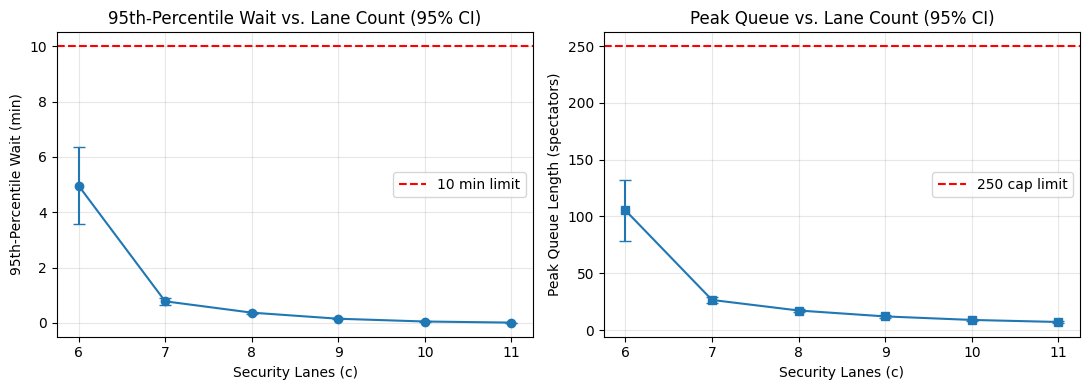

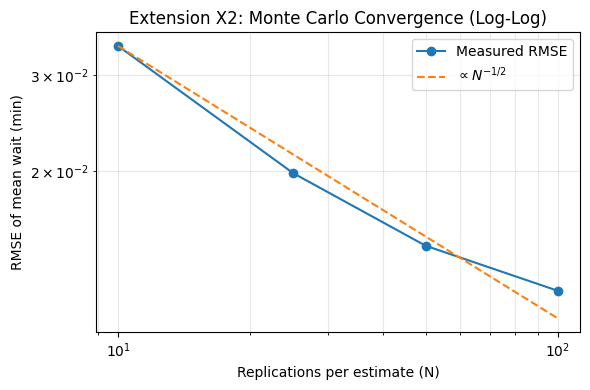

Extension X3 (Two-Stage Surge): {'mean_w1_min': 0.5165106660423651, 'mean_w2_min': 0.1062475152741721, 'peak_q1': 54, 'peak_q2': 19, 'arrivals': 1296, 'exits': 1296}


,lam,mu,rho,p95_wq_min,peak_q
0,15.0,2.5,0.75,0.41,16
1,15.0,3.0,0.62,0.13,11
2,15.0,3.5,0.54,0.05,7
3,18.0,2.5,0.90,0.70,29
4,18.0,3.0,0.75,0.33,16
5,18.0,3.5,0.64,0.12,9
6,21.0,2.5,1.05,6.99,179
7,21.0,3.0,0.88,0.81,31
8,21.0,3.5,0.75,0.27,16


In [15]:
def ci95_t(values):
    arr = np.asarray(values, dtype=float)
    mean = float(np.mean(arr))
    if len(arr) < 2:
        return mean, mean, mean
    half_width = float(stats.sem(arr) * stats.t.ppf(0.975, df=len(arr) - 1))
    return mean, mean - half_width, mean + half_width


lam_peak = 18.0
mu_lane = 3.0
safe_p95_limit = 10.0
safe_q_limit = 250

t0 = time.perf_counter()
sweep_rows = []
for c in range(6, 12):
    p95_vals, peakq_vals, meanw_vals = [], [], []
    for rep in range(25):
        out = simulate_mmc(lam_peak, mu_lane, c, sim_time=180.0, warmup=20.0, seed=2000 + c * 100 + rep)
        p95_vals.append(out["p95_wq"])
        peakq_vals.append(out["peak_q"])
        meanw_vals.append(out["mean_wq"])

    p95_m, p95_lo, p95_hi = ci95_t(p95_vals)
    pq_m, pq_lo, pq_hi = ci95_t(peakq_vals)
    mw_m, _, _ = ci95_t(meanw_vals)

    sweep_rows.append({
        "Lanes (c)": c,
        "rho": round(lam_peak / (c * mu_lane), 2),
        "Mean Wq (min)": round(mw_m, 2),
        "P95 Wait (min)": round(p95_m, 2),
        "P95 95% CI": f"[{p95_lo:.2f}, {p95_hi:.2f}]",
        "Peak Queue": round(pq_m, 1),
        "Peak Q 95% CI": f"[{pq_lo:.1f}, {pq_hi:.1f}]",
        "Meets Safety (<10m, <=250)": (p95_hi < safe_p95_limit) and (pq_hi <= safe_q_limit),
    })

df_sweep = pd.DataFrame(sweep_rows)
print(f"Lane sweep completed in {time.perf_counter() - t0:.2f} s")
display(df_sweep)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
c_vals = df_sweep["Lanes (c)"].to_numpy()
p95_means = df_sweep["P95 Wait (min)"].to_numpy()
p95_lows = np.array([float(s.split(",")[0].strip("[")) for s in df_sweep["P95 95% CI"]])
p95_highs = np.array([float(s.split(",")[1].strip("]")) for s in df_sweep["P95 95% CI"]])

axes[0].errorbar(c_vals, p95_means, yerr=[p95_means - p95_lows, p95_highs - p95_means], fmt="o-", capsize=4)
axes[0].axhline(safe_p95_limit, color="red", linestyle="--", label="10 min limit")
axes[0].set_xlabel("Security Lanes (c)")
axes[0].set_ylabel("95th-Percentile Wait (min)")
axes[0].set_title("95th-Percentile Wait vs. Lane Count (95% CI)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

pq_means = df_sweep["Peak Queue"].to_numpy()
pq_lows = np.array([float(s.split(",")[0].strip("[")) for s in df_sweep["Peak Q 95% CI"]])
pq_highs = np.array([float(s.split(",")[1].strip("]")) for s in df_sweep["Peak Q 95% CI"]])

axes[1].errorbar(c_vals, pq_means, yerr=[pq_means - pq_lows, pq_highs - pq_means], fmt="s-", capsize=4)
axes[1].axhline(safe_q_limit, color="red", linestyle="--", label="250 cap limit")
axes[1].set_xlabel("Security Lanes (c)")
axes[1].set_ylabel("Peak Queue Length (spectators)")
axes[1].set_title("Peak Queue vs. Lane Count (95% CI)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lane_sweep_ci95.png", dpi=150)
plt.show()

# Extension X2: Monte Carlo RMSE vs N on log-log scale
_, wq_true = erlang_c_metrics(10.0, 3.0, 4)
n_grid = [10, 25, 50, 100]
rmses = []
for n_rep in n_grid:
    est_means = []
    for m_trial in range(30):
        batch = [
            simulate_mmc(10.0, 3.0, 4, sim_time=300.0, warmup=50.0, seed=7000 + m_trial * 200 + k)["mean_wq"]
            for k in range(n_rep)
        ]
        est_means.append(np.mean(batch))
    rmses.append(math.sqrt(float(np.mean((np.array(est_means) - wq_true) ** 2))))

plt.figure(figsize=(6, 4))
plt.loglog(n_grid, rmses, "o-", label="Measured RMSE")
plt.loglog(n_grid, [rmses[0] * (n / n_grid[0]) ** (-0.5) for n in n_grid], "--", label=r"$\propto N^{-1/2}$")
plt.xlabel("Replications per estimate (N)")
plt.ylabel("RMSE of mean wait (min)")
plt.title("Extension X2: Monte Carlo Convergence (Log-Log)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("mc_error_scaling_x2.png", dpi=150)
plt.show()

# Extension X3: Two-stage surge simulation
surge_res = simulate_two_stage_surge(c_ticket=4, c_sec=8, mu_ticket=6.0, mu_sec=3.0, peak_lam=24.0, seed=4042)
print("Extension X3 (Two-Stage Surge):", surge_res)

# Extension X5: Sensitivity sweep across arrival rate and service rate at c = 8 lanes
sens_rows = []
for lam_s in [15.0, 18.0, 21.0]:
    for mu_s in [2.5, 3.0, 3.5]:
        r = simulate_mmc(lam_s, mu_s, c=8, sim_time=180.0, warmup=20.0, seed=8080)
        sens_rows.append({
            "lam": lam_s,
            "mu": mu_s,
            "rho": round(lam_s / (8 * mu_s), 2),
            "p95_wq_min": round(r["p95_wq"], 2),
            "peak_q": r["peak_q"],
        })
display(pd.DataFrame(sens_rows))


# 7. Discussion and Limitations
Adding security lanes lowers server utilization ($\rho$), reduces 95th-percentile waiting times, and curbs forecourt queue build-up. In the two-stage surge extension, comparing stage queue lengths and waits identifies whether ticket verification or security screening is the limiting stage during a pre-match surge.

**Limitations:** Parameters are synthetic/literature-grounded rather than collected from live gate counters, exponential service times simplify real screening variability, and a single-gate model excludes multi-gate crowd diversion and spatial pedestrian dynamics.


# 8. References
1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. McGraw-Hill, 2015.
2. D. Helbing and P. Molnár, "Social force model for pedestrian dynamics," *Phys. Rev. E*, vol. 51, no. 5, pp. 4282-4286, 1995, doi: 10.1103/PhysRevE.51.4282.
3. D. Helbing, I. Farkas, and T. Vicsek, "Simulating dynamical features of escape panic," *Nature*, vol. 407, pp. 487-490, 2000, doi: 10.1038/35035023.
4. L. Kleinrock, *Queueing Systems, Volume 1: Theory*. Wiley-Interscience, 1975.
